# Etapa 4 — Modelos, Avaliação e Comparação

Este notebook constrói e avalia modelos de classificação para demanda ordinal (0–4), seguindo a mesma organização de seções utilizada no `sales_etapa3.ipynb`.

> Objetivo: Treinar modelos (LogisticRegression, HistGradientBoosting e terceiro modelo: CatBoost se disponível, caso contrário RandomForest), validar por grupos (produto) com GroupKFold, avaliar em 2018, gerar relatório e visualizar matrizes de confusão.

## Seções
1. Configuração e Imports
2. Funções Utilitárias (pré-processamento, CV e avaliação)
3. Carregamento da Base de Dados
4. Derivação de Rótulos
5. Split Temporal (2015–17 / 2018)
6. Seleção de Features e Pré-processamento
7. Modelos e Validação por GroupKFold
8. Relatório e Visualizações
9. Visualizar Matrizes de Confusão (arquivos)
10. Reexibir Relatório após Nova Execução

## 1. Configuração e Imports

In [1]:
from __future__ import annotations
from pathlib import Path
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.exceptions import ConvergenceWarning
warnings.simplefilter(action='ignore', category=ConvergenceWarning)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier

# CatBoost é opcional; se não estiver disponível, usamos RandomForest como terceiro modelo
try:
    from catboost import CatBoostClassifier
    HAS_CATBOOST = True
except Exception:
    CatBoostClassifier = None
    HAS_CATBOOST = False

# XGBoost opcional
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except Exception:
    XGBClassifier = None
    HAS_XGB = False

# LightGBM opcional
try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except Exception:
    LGBMClassifier = None
    HAS_LGBM = False

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)


## 2. Funções Utilitárias (pré-processamento, CV e avaliação)

In [2]:
def load_data(csv_path: Path) -> pd.DataFrame:
    df = pd.read_csv(csv_path)
    df.columns = (
        df.columns
        .str.strip()
        .str.lower()
        .str.replace(' ', '_')
        .str.replace('-', '_')
    )
    if 'order_date' in df.columns:
        df['order_date'] = pd.to_datetime(df['order_date'], errors='coerce', dayfirst=True)
    if 'ship_date' in df.columns:
        df['ship_date'] = pd.to_datetime(df['ship_date'], errors='coerce', dayfirst=True)
    return df

def map_target(df: pd.DataFrame):
    ordinal_mapping = {'very low': 0, 'low': 1, 'neutral': 2, 'high': 3, 'very high': 4}
    df['demand_ord'] = df['demand'].map(ordinal_mapping).astype('int8')
    return ordinal_mapping

def derive_labels(df: pd.DataFrame) -> pd.DataFrame:
    product_demand = df.groupby('product_id')['sales'].sum().reset_index()
    labels = ['very low', 'low', 'neutral', 'high', 'very high']
    product_demand['demand'] = pd.qcut(product_demand['sales'], q=5, labels=labels)
    df = pd.merge(left=df, right=product_demand[['product_id','demand']], on='product_id', how='left')
    _ = map_target(df)
    return df

def split_train_test(df: pd.DataFrame):
    if 'order_date' not in df.columns:
        raise ValueError("Coluna 'order_date' não encontrada para efetuar split temporal")
    train_mask = df['order_date'].dt.year.isin([2015, 2016, 2017])
    test_mask = df['order_date'].dt.year == 2018
    df_train = df.loc[train_mask].reset_index(drop=True)
    df_test = df.loc[test_mask].reset_index(drop=True)
    return df_train, df_test

def select_features(df_train: pd.DataFrame, df_test: pd.DataFrame):
    cols_drop = ['demand', 'demand_ord', 'row_id', 'order_id', 'customer_name', 'product_name', 'order_date', 'ship_date']
    X_train = df_train.drop(columns=cols_drop + ['product_id'], errors='ignore')
    X_test = df_test.drop(columns=cols_drop + ['product_id'], errors='ignore')
    y_train = df_train['demand_ord']
    y_test = df_test['demand_ord']
    allowed_cats = {'ship_mode','segment','country','state','region','category','sub_category'}
    cat_cols = [c for c in X_train.columns if X_train[c].dtype == 'object' and c in allowed_cats]
    num_cols = [c for c in X_train.columns if X_train[c].dtype != 'object']
    return X_train, X_test, y_train, y_test, cat_cols, num_cols

def build_preprocessor(cat_cols, num_cols):
    categorical = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    numeric = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    preprocessor = ColumnTransformer(
        transformers=[
            ('categorical', categorical, cat_cols),
            ('numeric', numeric, num_cols)
        ],
        remainder='drop'
    )
    return preprocessor

def build_cat_features(X: pd.DataFrame):
    return [i for i, col in enumerate(X.columns) if X[col].dtype == 'object']

def run_groupkfold_cv(X: pd.DataFrame, y: pd.Series, groups: pd.Series, pipeline: Pipeline, n_splits: int = 5):
    gkf = GroupKFold(n_splits=n_splits)
    fold_acc = []
    oof_preds = np.empty(len(X), dtype=int)
    for fold_idx, (tr_idx, val_idx) in enumerate(gkf.split(X, y, groups)):
        X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
        y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]
        pipeline.fit(X_tr, y_tr)
        val_preds = pipeline.predict(X_val).astype(int)
        acc = accuracy_score(y_val, val_preds)
        fold_acc.append(acc)
        oof_preds[val_idx] = val_preds
        print(f"[CV] Fold {fold_idx+1}/{n_splits} acc={acc:.4f}")
    mean_acc = float(np.mean(fold_acc))
    std_acc = float(np.std(fold_acc))
    macro_f1 = float(f1_score(y, oof_preds, average='macro'))
    return mean_acc, std_acc, macro_f1

def run_catboost_groupkfold_cv(X: pd.DataFrame, y: pd.Series, groups: pd.Series, params: dict, n_splits: int = 5):
    if not HAS_CATBOOST:
        raise RuntimeError("CatBoost não disponível no ambiente")
    gkf = GroupKFold(n_splits=n_splits)
    fold_acc = []
    oof_preds = np.empty(len(X), dtype=int)
    cat_features = build_cat_features(X)
    for fold_idx, (tr_idx, val_idx) in enumerate(gkf.split(X, y, groups)):
        X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
        y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]
        model = CatBoostClassifier(
            loss_function='MultiClass',
            random_state=42,
            verbose=False,
            thread_count=-1,
            **params
        )
        model.fit(X_tr, y_tr, cat_features=cat_features)
        val_preds = model.predict(X_val).astype(int).flatten()
        acc = accuracy_score(y_val, val_preds)
        fold_acc.append(acc)
        oof_preds[val_idx] = val_preds
        print(f"[CV-CB] Fold {fold_idx+1}/{n_splits} acc={acc:.4f}")
    mean_acc = float(np.mean(fold_acc))
    std_acc = float(np.std(fold_acc))
    macro_f1 = float(f1_score(y, oof_preds, average='macro'))
    return mean_acc, std_acc, macro_f1

def eval_on_test(pipeline: Pipeline, X_train, y_train, X_test, y_test, fig_prefix: str):
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test).astype(int)
    acc = float(accuracy_score(y_test, y_pred))
    report = classification_report(y_test, y_pred, zero_division=0)
    cm = confusion_matrix(y_test, y_pred)
    fig, ax = plt.subplots(figsize=(7, 6))
    from sklearn.metrics import ConfusionMatrixDisplay
    ConfusionMatrixDisplay(confusion_matrix=cm).plot(ax=ax, cmap='Blues')
    ax.set_title(f'Matriz de Confusão — 2018 ({fig_prefix})')
    fig.tight_layout()
    out_dir = Path.cwd() / 'sales_files'
    out_dir.mkdir(parents=True, exist_ok=True)
    img_path = out_dir / f'cm_{fig_prefix}.png'
    fig.savefig(img_path)
    plt.close(fig)
    print(f"Figura de confusão salva em: {img_path}")
    return acc, report

def eval_catboost_on_test(X_train, y_train, X_test, y_test, params: dict, fig_prefix: str):
    if not HAS_CATBOOST:
        raise RuntimeError("CatBoost não disponível no ambiente")
    cat_features = build_cat_features(X_train)
    model = CatBoostClassifier(
        loss_function='MultiClass',
        random_state=42,
        verbose=False,
        thread_count=-1,
        **params
    )
    model.fit(X_train, y_train, cat_features=cat_features)
    y_pred = model.predict(X_test).astype(int).flatten()
    acc = float(accuracy_score(y_test, y_pred))
    report = classification_report(y_test, y_pred, zero_division=0)
    cm = confusion_matrix(y_test, y_pred)
    fig, ax = plt.subplots(figsize=(7, 6))
    from sklearn.metrics import ConfusionMatrixDisplay
    ConfusionMatrixDisplay(confusion_matrix=cm).plot(ax=ax, cmap='Blues')
    ax.set_title(f'Matriz de Confusão — 2018 ({fig_prefix})')
    fig.tight_layout()
    out_dir = Path.cwd() / 'sales_files'
    out_dir.mkdir(parents=True, exist_ok=True)
    img_path = out_dir / f'cm_{fig_prefix}.png'
    fig.savefig(img_path)
    plt.close(fig)
    print(f"Figura de confusão salva em: {img_path}")
    return acc, report

def write_report(md_path: Path, details: dict):
    lines = []
    lines.append("# Etapa 4 — Construção de Modelos, Avaliação e Comparação\n\n")
    lines.append("## Pré-processamento e Ajustes\n")
    lines.append('- Remoção de "product_id" dos features para evitar vazamento por produto.\n')
    lines.append("- Codificação categórica via OneHotEncoder em colunas de menor cardinalidade: ['ship_mode','segment','country','state','region','category','sub_category'].\n")
    lines.append("- Imputação: categóricas por moda, numéricas por mediana.\n")
    lines.append("- Validação por produto com GroupKFold (n_splits=5).\n\n")
    lines.append("## Modelos Implementados\n")
    lines.append("- LogisticRegression (multinomial, solver=saga): baseline linear, robusta em alta dimensionalidade após one-hot.\n")
    lines.append("- HistGradientBoostingClassifier: boosting baseado em histogramas, forte em dados tabulares.\n\n")
    lines.append("## Métrica Principal\n")
    lines.append("- Macro F1, com acurácia como métrica auxiliar.\n\n")
    for name, info in details.items():
        lines.append(f"### {name}\n")
        lines.append(f"- CV mean_acc = {info['cv_mean_acc']:.4f} ± {info['cv_std_acc']:.4f}\n")
        lines.append(f"- CV macro_f1 = {info['cv_macro_f1']:.4f}\n")
        lines.append(f"- Test 2018 acc = {info['test_acc']:.3f}\n")
        lines.append("- Classification Report (2018):\n")
        lines.append("```\n")
        lines.append(info['report_text'])
        lines.append("\n```\n\n")
    lines.append("## Comparação por Macro F1 (CV)\n")
    items = [(n, v['cv_macro_f1']) for n, v in details.items()]
    items_sorted = sorted(items, key=lambda x: x[1], reverse=True)
    for i, (n, score) in enumerate(items_sorted, start=1):
        lines.append(f"{i}. {n}: macro_f1={score:.4f}\n")
    lines.append("\n")
    lines.append("## Refinamento do Pipeline\n")
    lines.append("- Pipeline modular (pré-processamento + modelo), permitindo troca de algoritmos sem alterar etapas anteriores.\n")
    lines.append("- Suporte a validação por grupos e avaliação temporal (2018).\n")
    lines.append("- Próximos passos: ajuste fino de hiperparâmetros, inclusão de encoding mais eficiente para alta cardinalidade (e.g., target/frequency encoding), e comparação com modelos de gradient boosting adicionais.\n")
    md_path.write_text(''.join(lines), encoding='utf-8')
    print(f"Relatório gravado em: {md_path}")


## 3. Carregamento da Base de Dados

In [3]:
candidates = [Path('src/data/train.csv'), Path('data/train.csv')]
data_path = next((p for p in candidates if p.exists()), candidates[0])
print(f'Carregando dados de: {data_path.resolve() if data_path.exists() else data_path}')
df = load_data(data_path)
required = {"product_id", "sales", "order_date"}
missing = [c for c in required if c not in df.columns]
if missing:
    raise KeyError(f'Colunas necessárias ausentes: {missing}. Disponíveis: {list(df.columns)}')
df.head(3)


Carregando dados de: D:\Projeto\kfcaio-pmv-si-2025-2-pe7-t2-t1-g4\src\data\train.csv


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,state,postal_code,region,product_id,category,sub_category,product_name,sales
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62


## 4. Derivação de Rótulos

In [4]:
df = derive_labels(df)
df[['product_id','sales','demand','demand_ord']].head(5)


,product_id,sales,demand,demand_ord
0,FUR-BO-10001798,261.9600,high,3
1,FUR-CH-10000454,731.9400,very high,4
2,OFF-LA-10000240,14.6200,low,1
3,FUR-TA-10000577,957.5775,very high,4
4,OFF-ST-10000760,22.3680,neutral,2


## 5. Split Temporal (2015–17 / 2018)

In [5]:
df_train, df_test = split_train_test(df)
print(f'Tamanho train: {len(df_train)}; test: {len(df_test)}')


Tamanho train: 6542; test: 3258


## 6. Seleção de Features e Pré-processamento

In [6]:
X_train, X_test, y_train, y_test, cat_cols, num_cols = select_features(df_train, df_test)
groups = df_train['product_id']
preprocessor = build_preprocessor(cat_cols, num_cols)
print('Categóricas:', cat_cols)
print('Numéricas:', num_cols)


Categóricas: ['ship_mode', 'segment', 'country', 'state', 'region', 'category', 'sub_category']
Numéricas: ['postal_code', 'sales']


## 7. Modelos e Validação por GroupKFold

In [7]:
# Busca simples de C para LogisticRegression (macro F1 por GroupKFold)
details = {}
best_lr = None
best_lr_metrics = None
best_lr_macro_f1 = -1.0
C_grid = [0.5, 1.0, 2.0]
for C in C_grid:
    name = f'LogisticRegression_C{C}'
    est = LogisticRegression(C=C, penalty='l2', solver='lbfgs', max_iter=3000, tol=1e-3, multi_class='multinomial', class_weight='balanced')
    print(f"===== Rodando CV para {name} =====")
    pipe = Pipeline(steps=[('preprocess', preprocessor), ('model', est)])
    cv_mean_acc, cv_std_acc, cv_macro_f1 = run_groupkfold_cv(X_train, y_train, groups, pipe, n_splits=5)
    print(f'CV {name}: acc={cv_mean_acc:.4f} ± {cv_std_acc:.4f}, macro_f1={cv_macro_f1:.4f}')
    if cv_macro_f1 > best_lr_macro_f1:
        best_lr_macro_f1 = cv_macro_f1
        best_lr = est
        best_lr_metrics = (cv_mean_acc, cv_std_acc, cv_macro_f1)

# Avaliação em 2018 com melhor LogisticRegression
print('Avaliando melhor LogisticRegression em 2018...')
pipe = Pipeline(steps=[('preprocess', preprocessor), ('model', best_lr)])
test_acc, report_text = eval_on_test(pipe, X_train, y_train, X_test, y_test, fig_prefix=f'LogisticRegression_C{best_lr.C}')
print(report_text)
details['LogisticRegression'] = {
    'C': float(best_lr.C),
    'cv_mean_acc': float(best_lr_metrics[0]),
    'cv_std_acc': float(best_lr_metrics[1]),
    'cv_macro_f1': float(best_lr_metrics[2]),
    'test_acc': float(test_acc),
    'report_text': report_text
}

# Baseline: HistGradientBoosting
name = 'HistGradientBoosting'
est = HistGradientBoostingClassifier(max_depth=6, learning_rate=0.06, max_iter=300, random_state=42)
print(f"===== Rodando CV para {name} =====")
pipe = Pipeline(steps=[('preprocess', preprocessor), ('model', est)])
cv_mean_acc, cv_std_acc, cv_macro_f1 = run_groupkfold_cv(X_train, y_train, groups, pipe, n_splits=5)
print(f'CV {name}: acc={cv_mean_acc:.4f} ± {cv_std_acc:.4f}, macro_f1={cv_macro_f1:.4f}')
print(f'Avaliando {name} em 2018...')
test_acc, report_text = eval_on_test(pipe, X_train, y_train, X_test, y_test, fig_prefix=name)
print(report_text)
details[name] = {
    'cv_mean_acc': float(cv_mean_acc),
    'cv_std_acc': float(cv_std_acc),
    'cv_macro_f1': float(cv_macro_f1),
    'test_acc': float(test_acc),
    'report_text': report_text
}
if HAS_CATBOOST:
    print('===== Rodando CV para CatBoostClassifier =====')
    cb_params = {'iterations': 400, 'depth': 6, 'learning_rate': 0.06, 'l2_leaf_reg': 3}
    cv_mean_acc, cv_std_acc, cv_macro_f1 = run_catboost_groupkfold_cv(X_train, y_train, groups, cb_params, n_splits=5)
    print(f'CV CatBoostClassifier: acc={cv_mean_acc:.4f} ± {cv_std_acc:.4f}, macro_f1={cv_macro_f1:.4f}')
    print('Avaliando CatBoostClassifier em 2018...')
    test_acc, report_text = eval_catboost_on_test(X_train, y_train, X_test, y_test, cb_params, fig_prefix='CatBoostClassifier')
    print(report_text)
    details['CatBoostClassifier'] = {
        'cv_mean_acc': cv_mean_acc,
        'cv_std_acc': cv_std_acc,
        'cv_macro_f1': cv_macro_f1,
        'test_acc': test_acc,
        'report_text': report_text
    }
else:
    print('CatBoost indisponível; usando RandomForestClassifier como terceiro modelo.')
    rf = RandomForestClassifier(n_estimators=400, max_depth=None, random_state=42, n_jobs=-1)
    name = 'RandomForestClassifier'
    print(f'===== Rodando CV para {name} =====')
    pipe = Pipeline(steps=[('preprocess', preprocessor), ('model', rf)])
    cv_mean_acc, cv_std_acc, cv_macro_f1 = run_groupkfold_cv(X_train, y_train, groups, pipe, n_splits=5)
    print(f'CV {name}: acc={cv_mean_acc:.4f} ± {cv_std_acc:.4f}, macro_f1={cv_macro_f1:.4f}')
    print(f'Avaliando {name} em 2018...')
    test_acc, report_text = eval_on_test(pipe, X_train, y_train, X_test, y_test, fig_prefix=name)
    print(report_text)
    details[name] = {
        'cv_mean_acc': cv_mean_acc,
        'cv_std_acc': cv_std_acc,
        'cv_macro_f1': cv_macro_f1,
        'test_acc': test_acc,
        'report_text': report_text
    }


===== Rodando CV para LogisticRegression_C0.5 =====


[CV] Fold 1/5 acc=0.5286


[CV] Fold 2/5 acc=0.5363


[CV] Fold 3/5 acc=0.5245


[CV] Fold 4/5 acc=0.5306


...

[CV] Fold 2/5 acc=0.5325


[CV] Fold 3/5 acc=0.5275


[CV] Fold 4/5 acc=0.5321


[CV] Fold 5/5 acc=0.5566
CV RandomForestClassifier: acc=0.5312 ± 0.0157, macro_f1=0.5154
Avaliando RandomForestClassifier em 2018...


Figura de confusão salva em: D:\Projeto\kfcaio-pmv-si-2025-2-pe7-t2-t1-g4\sales_files\cm_RandomForestClassifier.png
              precision    recall  f1-score   support

           0       0.50      0.48      0.49       458
           1       0.45      0.49      0.47       659
           2       0.44      0.40      0.42       685
           3       0.49      0.48      0.48       698
           4       0.76      0.79      0.77       758

    accuracy                           0.54      3258
   macro avg       0.53      0.53      0.53      3258
weighted avg       0.54      0.54      0.54      3258



## 8. Relatório e Visualizações

In [8]:
from IPython.display import Markdown, display, Image
md_out = Path('relatorio_etapa4.md')
write_report(md_out, details)
display(Markdown(md_out.read_text()))
print('Relatório gravado em:', md_out.resolve())


Relatório gravado em: relatorio_etapa4.md


# Etapa 4 â€” ConstruÃ§Ã£o de Modelos, AvaliaÃ§Ã£o e ComparaÃ§Ã£o

## PrÃ©-processamento e Ajustes
- RemoÃ§Ã£o de "product_id" dos features para evitar vazamento por produto.
- CodificaÃ§Ã£o categÃ³rica via OneHotEncoder em colunas de menor cardinalidade: ['ship_mode','segment','country','state','region','category','sub_category'].
- ImputaÃ§Ã£o: categÃ³ricas por moda, numÃ©ricas por mediana.
- ValidaÃ§Ã£o por produto com GroupKFold (n_splits=5).

## Modelos Implementados
- LogisticRegression (multinomial, solver=saga): baseline linear, robusta em alta dimensionalidade apÃ³s one-hot.
- HistGradientBoostingClassifier: boosting baseado em histogramas, forte em dados tabulares.

## MÃ©trica Principal
- Macro F1, com acurÃ¡cia como mÃ©trica auxiliar.

### LogisticRegression
- CV mean_acc = 0.5550 Â± 0.0104
- CV macro_f1 = 0.5444
- Test 2018 acc = 0.565
- Classification Report (2018):
```
              precision    recall  f1-score   support

           0       0.46      0.63      0.53       458
           1       0.48      0.49      0.49       659
           2       0.48      0.43      0.45       685
           3       0.55      0.51      0.53       698
           4       0.84      0.76      0.80       758

    accuracy                           0.57      3258
   macro avg       0.56      0.57      0.56      3258
weighted avg       0.58      0.57      0.57      3258

```

### HistGradientBoosting
- CV mean_acc = 0.5593 Â± 0.0157
- CV macro_f1 = 0.5455
- Test 2018 acc = 0.571
- Classification Report (2018):
```
              precision    recall  f1-score   support

           0       0.58      0.48      0.53       458
           1       0.48      0.59      0.53       659
           2       0.49      0.43      0.46       685
           3       0.51      0.52      0.51       698
           4       0.78      0.78      0.78       758

    accuracy                           0.57      3258
   macro avg       0.57      0.56      0.56      3258
weighted avg       0.57      0.57      0.57      3258

```

### RandomForestClassifier
- CV mean_acc = 0.5312 Â± 0.0157
- CV macro_f1 = 0.5154
- Test 2018 acc = 0.538
- Classification Report (2018):
```
              precision    recall  f1-score   support

           0       0.50      0.48      0.49       458
           1       0.45      0.49      0.47       659
           2       0.44      0.40      0.42       685
           3       0.49      0.48      0.48       698
           4       0.76      0.79      0.77       758

    accuracy                           0.54      3258
   macro avg       0.53      0.53      0.53      3258
weighted avg       0.54      0.54      0.54      3258

```

## ComparaÃ§Ã£o por Macro F1 (CV)
1. HistGradientBoosting: macro_f1=0.5455
2. LogisticRegression: macro_f1=0.5444
3. RandomForestClassifier: macro_f1=0.5154

## Refinamento do Pipeline
- Pipeline modular (prÃ©-processamento + modelo), permitindo troca de algoritmos sem alterar etapas anteriores.
- Suporte a validaÃ§Ã£o por grupos e avaliaÃ§Ã£o temporal (2018).
- PrÃ³ximos passos: ajuste fino de hiperparÃ¢metros, inclusÃ£o de encoding mais eficiente para alta cardinalidade (e.g., target/frequency encoding), e comparaÃ§Ã£o com modelos de gradient boosting adicionais.


Relatório gravado em: D:\Projeto\kfcaio-pmv-si-2025-2-pe7-t2-t1-g4\relatorio_etapa4.md


## 9. Visualizar Matrizes de Confusão (arquivos)

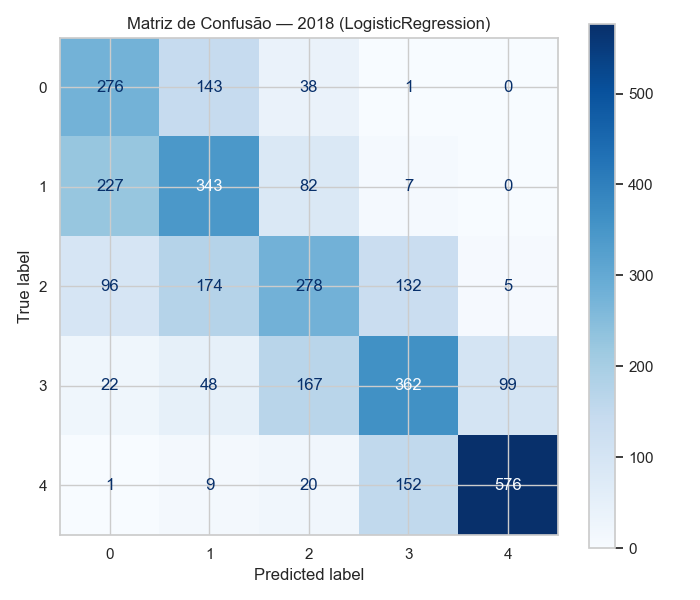

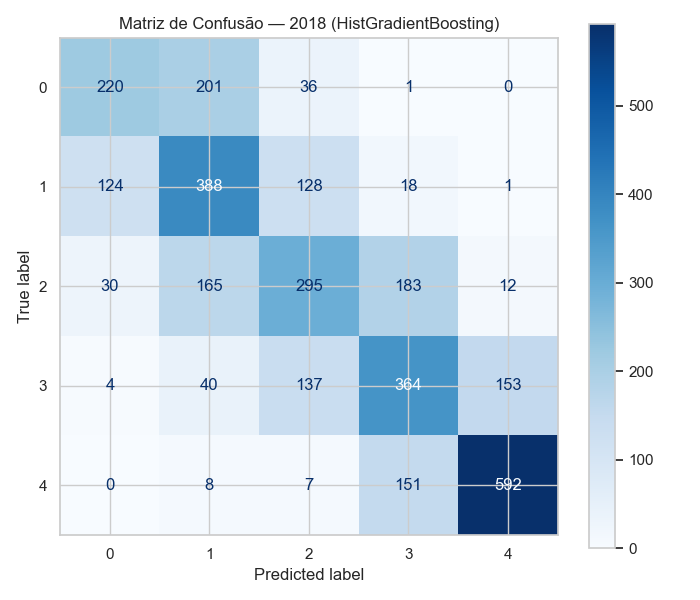

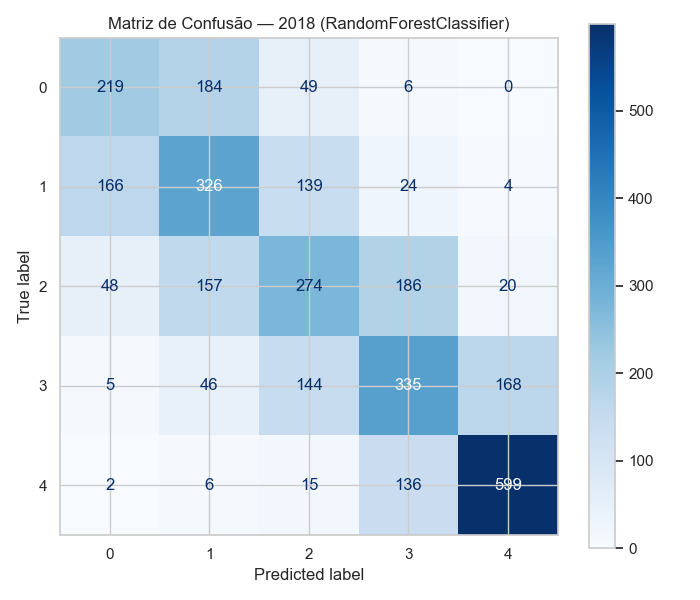

In [9]:
img_dir = Path('sales_files')
for name in details.keys():
    img_path = img_dir / f'cm_{name}.png'
    if img_path.exists():
        display(Image(filename=str(img_path)))
    else:
        print(f'Imagem não encontrada: {img_path}')


## 10. Reexibir Relatório após Nova Execução

In [10]:
# Útil após rodar novamente a geração (por exemplo, com ajustes nos modelos)
from IPython.display import Markdown, display
md_path = Path('relatorio_etapa4.md')
if md_path.exists():
    display(Markdown(md_path.read_text()))
else:
    print('relatorio_etapa4.md ainda não existe; execute as células de geração acima.')


# Etapa 4 â€” ConstruÃ§Ã£o de Modelos, AvaliaÃ§Ã£o e ComparaÃ§Ã£o

## PrÃ©-processamento e Ajustes
- RemoÃ§Ã£o de "product_id" dos features para evitar vazamento por produto.
- CodificaÃ§Ã£o categÃ³rica via OneHotEncoder em colunas de menor cardinalidade: ['ship_mode','segment','country','state','region','category','sub_category'].
- ImputaÃ§Ã£o: categÃ³ricas por moda, numÃ©ricas por mediana.
- ValidaÃ§Ã£o por produto com GroupKFold (n_splits=5).

## Modelos Implementados
- LogisticRegression (multinomial, solver=saga): baseline linear, robusta em alta dimensionalidade apÃ³s one-hot.
- HistGradientBoostingClassifier: boosting baseado em histogramas, forte em dados tabulares.

## MÃ©trica Principal
- Macro F1, com acurÃ¡cia como mÃ©trica auxiliar.

### LogisticRegression
- CV mean_acc = 0.5550 Â± 0.0104
- CV macro_f1 = 0.5444
- Test 2018 acc = 0.565
- Classification Report (2018):
```
              precision    recall  f1-score   support

           0       0.46      0.63      0.53       458
           1       0.48      0.49      0.49       659
           2       0.48      0.43      0.45       685
           3       0.55      0.51      0.53       698
           4       0.84      0.76      0.80       758

    accuracy                           0.57      3258
   macro avg       0.56      0.57      0.56      3258
weighted avg       0.58      0.57      0.57      3258

```

### HistGradientBoosting
- CV mean_acc = 0.5593 Â± 0.0157
- CV macro_f1 = 0.5455
- Test 2018 acc = 0.571
- Classification Report (2018):
```
              precision    recall  f1-score   support

           0       0.58      0.48      0.53       458
           1       0.48      0.59      0.53       659
           2       0.49      0.43      0.46       685
           3       0.51      0.52      0.51       698
           4       0.78      0.78      0.78       758

    accuracy                           0.57      3258
   macro avg       0.57      0.56      0.56      3258
weighted avg       0.57      0.57      0.57      3258

```

### RandomForestClassifier
- CV mean_acc = 0.5312 Â± 0.0157
- CV macro_f1 = 0.5154
- Test 2018 acc = 0.538
- Classification Report (2018):
```
              precision    recall  f1-score   support

           0       0.50      0.48      0.49       458
           1       0.45      0.49      0.47       659
           2       0.44      0.40      0.42       685
           3       0.49      0.48      0.48       698
           4       0.76      0.79      0.77       758

    accuracy                           0.54      3258
   macro avg       0.53      0.53      0.53      3258
weighted avg       0.54      0.54      0.54      3258

```

## ComparaÃ§Ã£o por Macro F1 (CV)
1. HistGradientBoosting: macro_f1=0.5455
2. LogisticRegression: macro_f1=0.5444
3. RandomForestClassifier: macro_f1=0.5154

## Refinamento do Pipeline
- Pipeline modular (prÃ©-processamento + modelo), permitindo troca de algoritmos sem alterar etapas anteriores.
- Suporte a validaÃ§Ã£o por grupos e avaliaÃ§Ã£o temporal (2018).
- PrÃ³ximos passos: ajuste fino de hiperparÃ¢metros, inclusÃ£o de encoding mais eficiente para alta cardinalidade (e.g., target/frequency encoding), e comparaÃ§Ã£o com modelos de gradient boosting adicionais.
